Correlation matrix built for 60-day window ending 2008-10-15.
Network created with 300 connected nodes and 28195 edges (Threshold > 0.55).
Network Density: 0.6287
Average 60-day Correlation: 0.5831


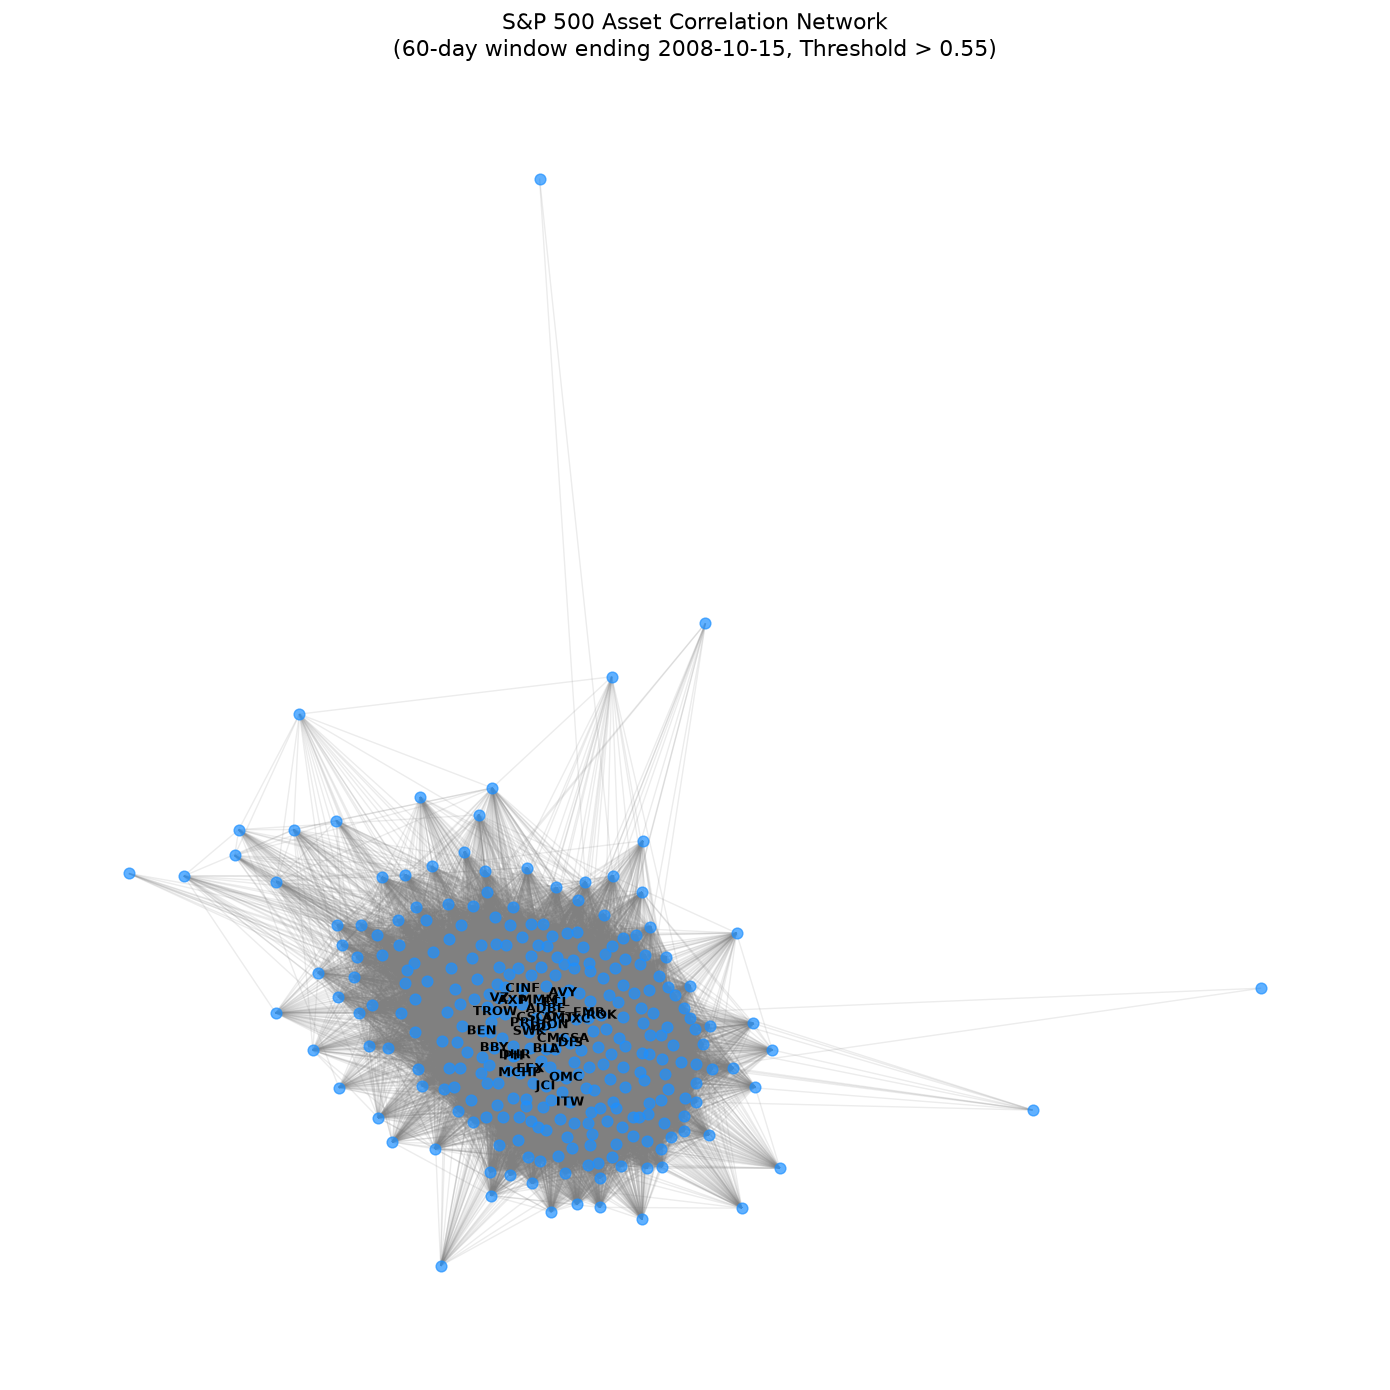

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from src.windows import correlation_at

def build_network():
    # ---------------------------------------------------------
    # Task 1: Build a correlation matrix for one 60-day window
    # ---------------------------------------------------------
    # Load the processed daily returns. 
    # (Adjust the path if the processed file is named or located differently)
    try:
        returns = pd.read_parquet('data/processed/returns_daily.parquet')
    except FileNotFoundError:
        print("Processed returns not found.")
        return

    # Select a target date to analyze a trailing 60-day window (e.g., the 2008 financial crisis)
    target_date = '2008-10-15'
    
    # Generate the correlation matrix
    corr_matrix = correlation_at(returns, end=target_date, window=60)
    print(f"Correlation matrix built for 60-day window ending {target_date}.")

    # ---------------------------------------------------------
    # Task 2: Convert it to a network using a correlation threshold
    # ---------------------------------------------------------
    threshold = 0.55

    # Create adjacency matrix: 1 if absolute correlation > threshold, else 0
    adjacency_matrix = (corr_matrix.abs() > threshold).astype(int)
    
    # Convert the pandas adjacency matrix to a NetworkX graph right away
    G = nx.from_pandas_adjacency(adjacency_matrix)

    # Tell NetworkX to remove all self-loops (where a stock connects to itself)
    G.remove_edges_from(nx.selfloop_edges(G))

    # Remove isolated nodes (assets with no strong correlations) for a cleaner analysis
    isolates = list(nx.isolates(G))
    G.remove_nodes_from(isolates)
    print(f"Network created with {G.number_of_nodes()} connected nodes and {G.number_of_edges()} edges (Threshold > {threshold}).")

    # ---------------------------------------------------------
    # Task 3: Compute density and average correlation
    # ---------------------------------------------------------
    # Calculate network density
    network_density = nx.density(G)

    # Calculate average correlation (mean of the upper triangle of the correlation matrix)
    upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    avg_correlation = upper_triangle.mean().mean()

    print(f"Network Density: {network_density:.4f}")
    print(f"Average 60-day Correlation: {avg_correlation:.4f}")

    # ---------------------------------------------------------
    # Task 4: Visualize the network
    # ---------------------------------------------------------
    plt.figure(figsize=(14, 14))
    plt.title(f"S&P 500 Asset Correlation Network\n(60-day window ending {target_date}, Threshold > {threshold})", fontsize=16)

    # Use a spring layout to group highly correlated assets closer together
    pos = nx.spring_layout(G, seed=42, k=0.15)

    # Draw nodes and edges
    nx.draw_networkx_nodes(G, pos, node_size=60, node_color='dodgerblue', alpha=0.7)
    nx.draw_networkx_edges(G, pos, alpha=0.15, edge_color='gray')

    # Label only the most highly connected nodes (hubs) to avoid text overlap
    degrees = dict(G.degree())
    if degrees:
        degree_threshold = np.percentile(list(degrees.values()), 90)
        high_degree_nodes = [node for node, degree in degrees.items() if degree > degree_threshold]
        labels = {node: node for node in high_degree_nodes}
        nx.draw_networkx_labels(G, pos, labels=labels, font_size=9, font_color='black', font_weight='bold')

    plt.axis('off')
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    build_network()